# **1. Perkenalan Dataset**


# 1. Perkenalan Dataset

Dataset yang digunakan dalam proyek ini adalah **Air Quality Dataset** yang diperoleh dari Kaggle.

**Sumber Dataset:** https://www.kaggle.com/datasets/srisyra02/air-quality-dataset

Dataset ini berisi informasi mengenai kualitas udara berdasarkan beberapa parameter polutan dan kondisi lingkungan. Dataset digunakan untuk memahami karakteristik data kualitas udara serta melakukan tahapan *Exploratory Data Analysis* (EDA) dan *data preprocessing* sebelum digunakan dalam proses pemodelan *machine learning*.

## Informasi Dataset

Dataset ini memiliki beberapa kolom yang berkaitan dengan konsentrasi polutan udara dan kondisi lingkungan, yaitu:

| No. | Nama Kolom | Deskripsi |
|---|---|---|
| 1 | `PM2.5` | Partikel halus di udara dengan diameter 2,5 mikrometer atau lebih kecil. |
| 2 | `PM10` | Partikel di udara dengan diameter 10 mikrometer atau lebih kecil. |
| 3 | `NOx` | Kelompok oksida nitrogen yang dihasilkan, antara lain, dari proses pembakaran. |
| 4 | `NO2` | Nitrogen dioksida, salah satu polutan udara yang dapat berasal dari aktivitas kendaraan dan industri. |
| 5 | `SO2` | Sulfur dioksida, gas pencemar yang dapat dihasilkan dari pembakaran bahan bakar yang mengandung sulfur. |
| 6 | `VOCs` | *Volatile Organic Compounds*, yaitu senyawa organik yang mudah menguap dan dapat berkontribusi terhadap pencemaran udara. |
| 7 | `CO` | Karbon monoksida, gas yang dihasilkan dari pembakaran tidak sempurna. |
| 8 | `CO2` | Karbon dioksida, gas yang dihasilkan dari proses pembakaran dan aktivitas biologis. |
| 9 | `CH4` | Metana, gas yang dapat berasal dari aktivitas industri, pertanian, dan penguraian bahan organik. |
| 10 | `Temperature` | Suhu lingkungan yang dapat memengaruhi kondisi dan karakteristik kualitas udara. |

## Tujuan Penggunaan Dataset

Dataset ini digunakan untuk melakukan analisis awal terhadap distribusi parameter kualitas udara, mengidentifikasi nilai kosong dan data duplikat, memeriksa hubungan antarfitur, serta membersihkan data sebelum digunakan untuk analisis atau pemodelan lebih lanjut.

Tahapan pengolahan data meliputi *data loading*, EDA, penanganan *missing values*, penghapusan duplikasi, penanganan *outlier*, dan encoding fitur kategorikal apabila diperlukan. Hasil akhir preprocessing disimpan dalam file `preprocessed_data.csv`.

**Catatan:** Nama kolom dan deskripsi di atas mengikuti informasi kolom yang diberikan. Satuan pengukuran, jumlah baris, dan definisi spesifik setiap fitur perlu dikonfirmasi berdasarkan berkas CSV asli dari Kaggle.

# **2. Import Library**

Pada tahap ini, Anda perlu mengimpor beberapa pustaka (library) Python yang dibutuhkan untuk analisis data dan pembangunan model machine learning atau deep learning.

In [1]:
# Mengimpor library untuk pengolahan dan analisis data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.preprocessing import StandardScaler

# Mengatur tampilan dataframe dan visualisasi
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

print("Library berhasil diimpor.")

Library berhasil diimpor.


# **3. Memuat Dataset**

Pada tahap ini, Anda perlu memuat dataset ke dalam notebook. Jika dataset dalam format CSV, Anda bisa menggunakan pustaka pandas untuk membacanya. Pastikan untuk mengecek beberapa baris awal dataset untuk memahami strukturnya dan memastikan data telah dimuat dengan benar.

Jika dataset berada di Google Drive, pastikan Anda menghubungkan Google Drive ke Colab terlebih dahulu. Setelah dataset berhasil dimuat, langkah berikutnya adalah memeriksa kesesuaian data dan siap untuk dianalisis lebih lanjut.

Jika dataset berupa unstructured data, silakan sesuaikan dengan format seperti kelas Machine Learning Pengembangan atau Machine Learning Terapan

In [2]:
df = pd.read_csv("/content/air_quality_dataset.csv")
display(df.head())

,PM2.5,PM10,NOx,NO2,SO2,VOCs,CO,CO2,CH4,Temperature
0,39.967142,57.926035,116.192213,55.230299,4.531693,75.317261,2.789606,427.674347,1.706105,31.085120
1,101.935672,150.774299,76.826826,79.051618,18.744780,145.083987,1.966569,529.739619,2.492663,33.711103
2,70.996192,138.948796,158.731020,60.466604,14.892239,145.147338,2.626446,499.889443,2.431165,33.778698
3,28.464728,63.643900,25.385343,15.333286,7.647429,130.022319,1.779360,388.283712,1.818563,31.565877
4,78.265276,113.977926,105.644340,59.202337,17.696806,181.713667,3.240533,464.739197,2.597225,32.229835


# **4. Exploratory Data Analysis (EDA)**

Pada tahap ini, Anda akan melakukan **Exploratory Data Analysis (EDA)** untuk memahami karakteristik dataset.

Tujuan dari EDA adalah untuk memperoleh wawasan awal yang mendalam mengenai data dan menentukan langkah selanjutnya dalam analisis atau pemodelan.

In [3]:
# Informasi dataset
print("Informasi Dataset:")
df.info()

print("\nJumlah baris dan kolom:", df.shape)
print("\nNama kolom:")
print(df.columns.tolist())

print("\nTipe data setiap kolom:")
display(df.dtypes.to_frame(name="Tipe Data"))

Informasi Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PM2.5        500 non-null    float64
 1   PM10         500 non-null    float64
 2   NOx          500 non-null    float64
 3   NO2          500 non-null    float64
 4   SO2          500 non-null    float64
 5   VOCs         500 non-null    float64
 6   CO           500 non-null    float64
 7   CO2          500 non-null    float64
 8   CH4          500 non-null    float64
 9   Temperature  500 non-null    float64
dtypes: float64(10)
memory usage: 39.2 KB

Jumlah baris dan kolom: (500, 10)

Nama kolom:
['PM2.5', 'PM10', 'NOx', 'NO2', 'SO2', 'VOCs', 'CO', 'CO2', 'CH4', 'Temperature']

Tipe data setiap kolom:


,Tipe Data
PM2.5,float64
PM10,float64
NOx,float64
NO2,float64
SO2,float64
VOCs,float64
CO,float64
CO2,float64
CH4,float64
Temperature,float64


In [4]:
# Statistik deskriptif untuk seluruh kolom
display(df.describe(include="all").T)

,count,mean,std,min,25%,50%,75%,max
PM2.5,500.0,54.671620,22.799473,10.757597,36.372940,48.038599,73.820566,127.616632
PM10,500.0,84.703251,30.567912,12.932337,61.118607,78.135558,110.270086,171.594187
NOx,500.0,91.814080,54.808414,-0.076323,35.457263,95.452284,134.709240,225.886935
NO2,500.0,42.410820,26.343669,-1.942140,17.448632,39.211583,63.817763,115.916428
SO2,500.0,11.504816,7.306978,-1.095555,5.976492,8.681222,17.116673,31.941860
VOCs,500.0,112.193098,39.471686,27.555617,81.516729,104.819124,140.588100,231.926017
CO,500.0,2.177705,0.824762,0.366992,1.536915,2.045519,2.726020,4.798935
CO2,500.0,439.288087,51.220578,366.063158,397.399610,420.934319,490.968315,558.924256
CH4,500.0,2.130439,0.391396,1.388407,1.837395,2.066709,2.386267,3.352266
Temperature,500.0,30.448413,2.957290,19.581349,28.481974,30.432756,32.614954,39.778713


In [5]:
# Jumlah missing values
missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Jumlah Missing Values": missing_values,
    "Persentase Missing (%)": (
        missing_values / len(df) * 100
    ).round(2)
})

display(missing_summary)

# Memeriksa jumlah baris duplikat
print("Jumlah baris duplikat:", df.duplicated().sum())

,Jumlah Missing Values,Persentase Missing (%)
PM2.5,0,0.0
PM10,0,0.0
NOx,0,0.0
NO2,0,0.0
SO2,0,0.0
VOCs,0,0.0
CO,0,0.0
CO2,0,0.0
CH4,0,0.0
Temperature,0,0.0


Jumlah baris duplikat: 0


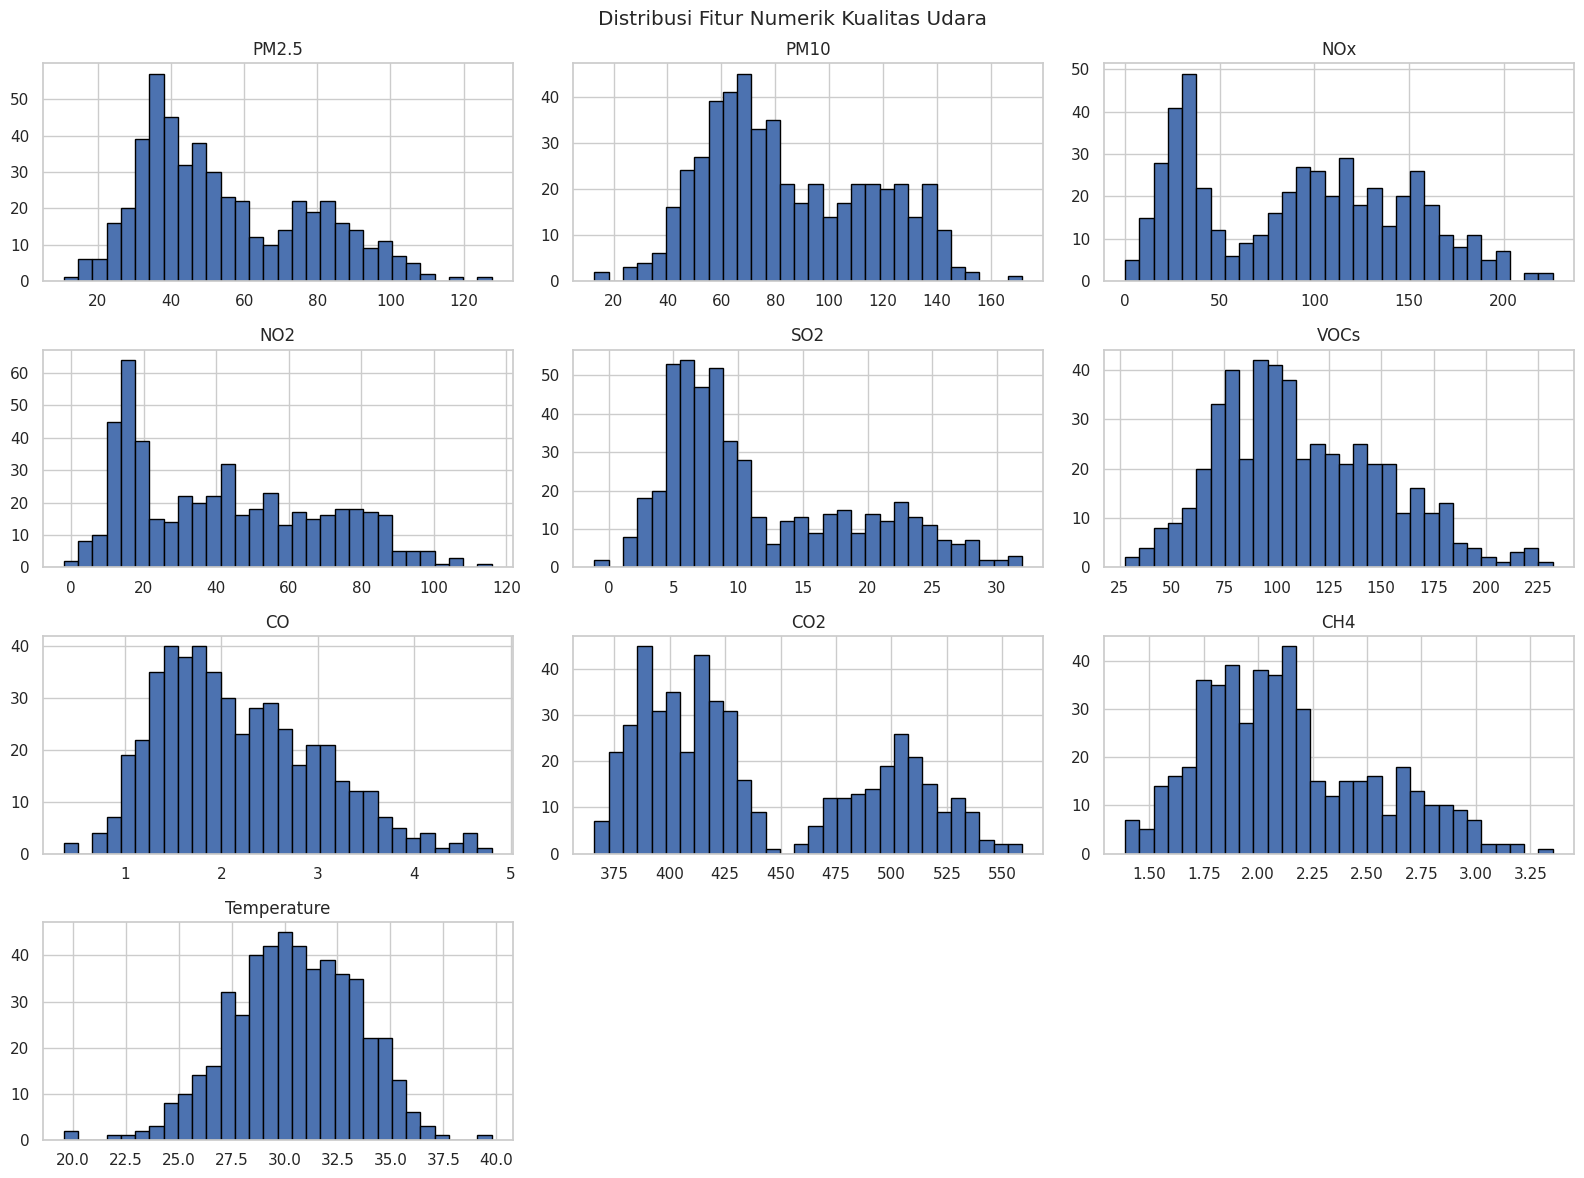

In [6]:
# Memilih kolom numerik
numeric_columns = df.select_dtypes(include=np.number).columns

if len(numeric_columns) > 0:
    df[numeric_columns].hist(
        figsize=(16, 12),
        bins=30,
        edgecolor="black"
    )
    plt.suptitle("Distribusi Fitur Numerik Kualitas Udara")
    plt.tight_layout()
    plt.show()
else:
    print("Tidak ditemukan kolom numerik.")

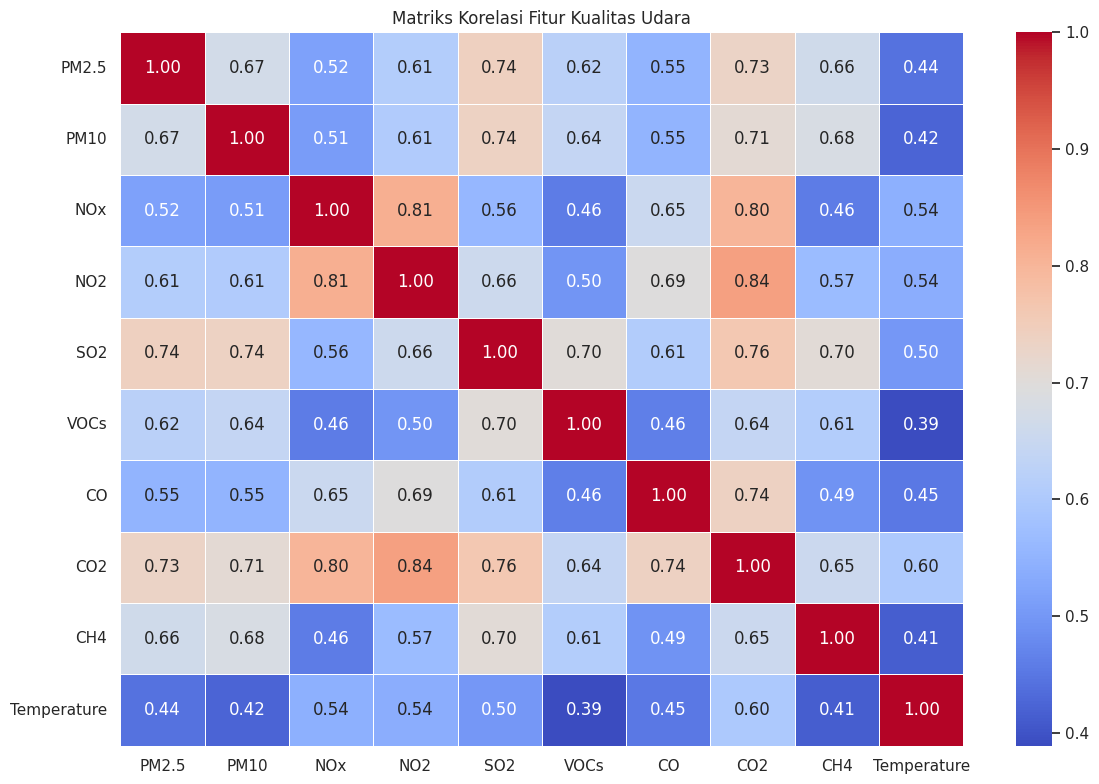

In [7]:
if len(numeric_columns) > 1:
    plt.figure(figsize=(12, 8))

    sns.heatmap(
        df[numeric_columns].corr(),
        annot=True,
        cmap="coolwarm",
        fmt=".2f",
        linewidths=0.5
    )

    plt.title("Matriks Korelasi Fitur Kualitas Udara")
    plt.tight_layout()
    plt.show()

# **5. Data Preprocessing**

Pada tahap ini, data preprocessing adalah langkah penting untuk memastikan kualitas data sebelum digunakan dalam model machine learning.

Jika Anda menggunakan data teks, data mentah sering kali mengandung nilai kosong, duplikasi, atau rentang nilai yang tidak konsisten, yang dapat memengaruhi kinerja model. Oleh karena itu, proses ini bertujuan untuk membersihkan dan mempersiapkan data agar analisis berjalan optimal.

Berikut adalah tahapan-tahapan yang bisa dilakukan, tetapi **tidak terbatas** pada:
1. Menghapus atau Menangani Data Kosong (Missing Values)
2. Menghapus Data Duplikat
3. Normalisasi atau Standarisasi Fitur
4. Deteksi dan Penanganan Outlier
5. Encoding Data Kategorikal
6. Binning (Pengelompokan Data)

Cukup sesuaikan dengan karakteristik data yang kamu gunakan yah. Khususnya ketika kami menggunakan data tidak terstruktur.

In [8]:
# Membuat salinan agar dataset asli tetap terjaga
df_clean = df.copy()

# Membersihkan spasi pada nama kolom
df_clean.columns = df_clean.columns.astype(str).str.strip()

# Menghapus kolom indeks yang tidak diperlukan
unnamed_columns = [
    col for col in df_clean.columns
    if col.lower().startswith("unnamed:")
]

df_clean.drop(columns=unnamed_columns, inplace=True)

# Mengubah nilai tak hingga menjadi missing values
df_clean.replace([np.inf, -np.inf], np.nan, inplace=True)

# Menghapus baris duplikat
df_clean.drop_duplicates(inplace=True)

print("Ukuran dataset sebelum preprocessing:", df.shape)
print("Ukuran dataset setelah menghapus duplikasi:", df_clean.shape)

display(df_clean.head())

Ukuran dataset sebelum preprocessing: (500, 10)
Ukuran dataset setelah menghapus duplikasi: (500, 10)


,PM2.5,PM10,NOx,NO2,SO2,VOCs,CO,CO2,CH4,Temperature
0,39.967142,57.926035,116.192213,55.230299,4.531693,75.317261,2.789606,427.674347,1.706105,31.085120
1,101.935672,150.774299,76.826826,79.051618,18.744780,145.083987,1.966569,529.739619,2.492663,33.711103
2,70.996192,138.948796,158.731020,60.466604,14.892239,145.147338,2.626446,499.889443,2.431165,33.778698
3,28.464728,63.643900,25.385343,15.333286,7.647429,130.022319,1.779360,388.283712,1.818563,31.565877
4,78.265276,113.977926,105.644340,59.202337,17.696806,181.713667,3.240533,464.739197,2.597225,32.229835


In [9]:
# Mengidentifikasi kolom berdasarkan tipe data
numeric_columns = df_clean.select_dtypes(
    include=np.number
).columns.tolist()

categorical_columns = df_clean.select_dtypes(
    include=["object", "category", "string", "bool"]
).columns.tolist()

# Mengisi missing values pada kolom numerik
for col in numeric_columns:
    if df_clean[col].isnull().any():
        median_value = df_clean[col].median()

        if pd.notna(median_value):
            df_clean[col] = df_clean[col].fillna(median_value)

# Mengisi missing values pada kolom kategorikal
for col in categorical_columns:
    if df_clean[col].isnull().any():
        mode_values = df_clean[col].mode(dropna=True)

        if not mode_values.empty:
            df_clean[col] = df_clean[col].fillna(mode_values.iloc[0])
        else:
            df_clean[col] = df_clean[col].fillna("Unknown")

print("Total missing values setelah penanganan:",
      df_clean.isnull().sum().sum())

Total missing values setelah penanganan: 0


In [10]:
# Memperbarui kolom numerik setelah pembersihan
numeric_columns = df_clean.select_dtypes(
    include=np.number
).columns.tolist()

outlier_summary = []

for col in numeric_columns:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Menghitung jumlah outlier sebelum penanganan
    outlier_count = (
        (df_clean[col] < lower_bound) |
        (df_clean[col] > upper_bound)
    ).sum()

    # Membatasi nilai ekstrem
    df_clean[col] = df_clean[col].clip(
        lower=lower_bound,
        upper=upper_bound
    )

    outlier_summary.append({
        "Kolom": col,
        "Jumlah Outlier Sebelum Penanganan": int(outlier_count),
        "Batas Bawah": lower_bound,
        "Batas Atas": upper_bound
    })

display(pd.DataFrame(outlier_summary))

,Kolom,Jumlah Outlier Sebelum Penanganan,Batas Bawah,Batas Atas
0,PM2.5,0,-19.798501,129.992007
1,PM10,0,-12.608611,183.997305
2,NOx,0,-113.420703,283.587206
3,NO2,0,-52.105064,133.371459
4,SO2,0,-10.733779,33.826944
5,VOCs,1,-7.090328,229.195157
6,CO,5,-0.246743,4.509678
7,CO2,0,257.046553,631.321371
8,CH4,3,1.014088,3.209574
9,Temperature,4,22.282505,38.814424


In [11]:
categorical_columns = df_clean.select_dtypes(
    include=["object", "category", "string", "bool"]
).columns.tolist()

if categorical_columns:
    df_clean = pd.get_dummies(
        df_clean,
        columns=categorical_columns,
        dtype=int
    )

print("Ukuran dataset setelah encoding:", df_clean.shape)
display(df_clean.head())

Ukuran dataset setelah encoding: (500, 10)


,PM2.5,PM10,NOx,NO2,SO2,VOCs,CO,CO2,CH4,Temperature
0,39.967142,57.926035,116.192213,55.230299,4.531693,75.317261,2.789606,427.674347,1.706105,31.085120
1,101.935672,150.774299,76.826826,79.051618,18.744780,145.083987,1.966569,529.739619,2.492663,33.711103
2,70.996192,138.948796,158.731020,60.466604,14.892239,145.147338,2.626446,499.889443,2.431165,33.778698
3,28.464728,63.643900,25.385343,15.333286,7.647429,130.022319,1.779360,388.283712,1.818563,31.565877
4,78.265276,113.977926,105.644340,59.202337,17.696806,181.713667,3.240533,464.739197,2.597225,32.229835


In [12]:
# Pemeriksaan akhir
print("Jumlah missing values:", df_clean.isnull().sum().sum())
print("Jumlah baris duplikat:", df_clean.duplicated().sum())
print("Ukuran akhir dataset:", df_clean.shape)

display(df_clean.head())

# Menyimpan hasil preprocessing
output_path = Path("preprocessed_data.csv")
df_clean.to_csv(output_path, index=False)

print(f"\nDataset hasil preprocessing berhasil disimpan: {output_path}")

Jumlah missing values: 0
Jumlah baris duplikat: 0
Ukuran akhir dataset: (500, 10)


,PM2.5,PM10,NOx,NO2,SO2,VOCs,CO,CO2,CH4,Temperature
0,39.967142,57.926035,116.192213,55.230299,4.531693,75.317261,2.789606,427.674347,1.706105,31.085120
1,101.935672,150.774299,76.826826,79.051618,18.744780,145.083987,1.966569,529.739619,2.492663,33.711103
2,70.996192,138.948796,158.731020,60.466604,14.892239,145.147338,2.626446,499.889443,2.431165,33.778698
3,28.464728,63.643900,25.385343,15.333286,7.647429,130.022319,1.779360,388.283712,1.818563,31.565877
4,78.265276,113.977926,105.644340,59.202337,17.696806,181.713667,3.240533,464.739197,2.597225,32.229835



Dataset hasil preprocessing berhasil disimpan: preprocessed_data.csv
